In [1]:
from datetime import date

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
import yaml

from common import daterange


In [2]:
dates = []
for i in daterange(date(2025, 12, 1), date(2025, 12, 31)):
    dates.append(i)

empty = pl.DataFrame({"day": dates})

In [3]:
with open("../config.budapest.yaml") as fp:
    config = yaml.safe_load(fp)
with open("plotting_config.yaml") as fp:
    plotting_config = yaml.safe_load(fp)

In [13]:
RES = 8
AGGREGATION = "device"  # device | trip
EVALUATION = "relaxed"  # strict | relaxed
DIR = f"{config['dirs']['output']}/{config['city']}"

In [14]:
daily_comm = pl.read_csv(
    f"{DIR}/dynamic_commuting/{RES}/{AGGREGATION}/{EVALUATION}/daily_commuting.csv"
)

In [15]:
daily_comm

day,h3_8_home,h3_8_work,count
str,str,str,i64
"""2023-10-02""","""881e03002dfffff""","""881e03002dfffff""",1
"""2023-10-02""","""881e03005dfffff""","""881e03005dfffff""",1
"""2023-10-02""","""881e030067fffff""","""881e030067fffff""",2
"""2023-10-02""","""881e0300bbfffff""","""881e0300bbfffff""",6
"""2023-10-02""","""881e030141fffff""","""881e030141fffff""",1
…,…,…,…
"""2025-12-31""","""881e1dd9e3fffff""","""881e1dd9e3fffff""",3
"""2025-12-31""","""881e1ddb1bfffff""","""881e1ddb1bfffff""",1
"""2025-12-31""","""881e1ddb2dfffff""","""881e1ddb2dfffff""",2


In [16]:
daily = daily_comm.group_by("day").agg(pl.col.count.sum()).sort("day")
daily = daily.with_columns(pl.col.day.str.to_date("%Y-%m-%d"))

In [17]:
to_plot = (
    pl.concat(
        [daily.filter(pl.col.day >= date(2025, 1, 1)), empty],
        how="diagonal",
    )
    .unique(subset=["day"], keep="first")
    .sort("day")
    .to_pandas()
)

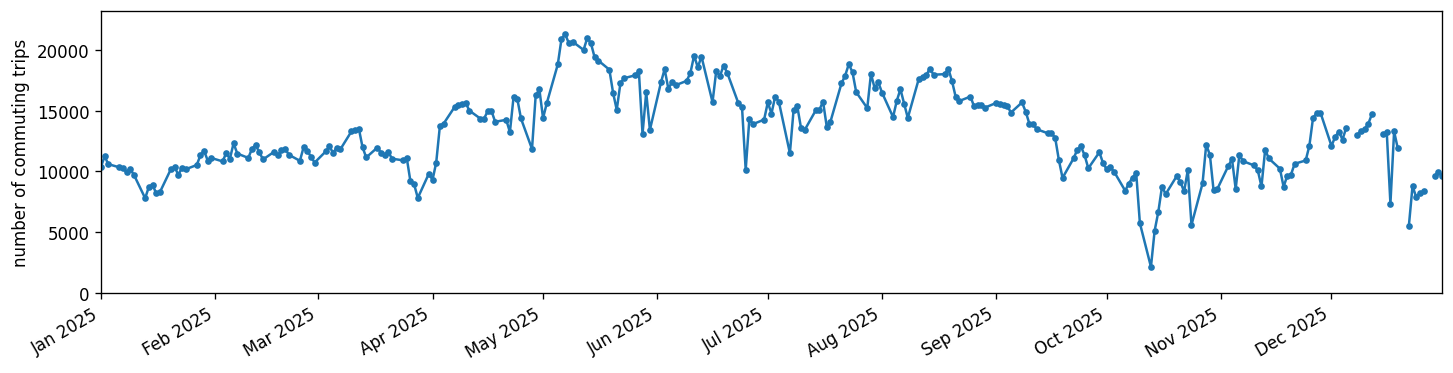

In [18]:
fig, ax = plt.subplots(layout="constrained", dpi=120, figsize=(12, 3))
to_plot[to_plot["day"] >= "2025-01-01"].plot(
    ax=ax, x="day", y="count", legend=False, marker="."
)
ax.margins(0, 0.1)
ax.set_ylim(bottom=0)
ax.set_xlabel("")
ax.set_ylabel("number of commuting trips")

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.autofmt_xdate()
for i in ["png"]:
    fig.savefig(
        f"../docs/figures/{EVALUATION}_daily_commutings_2025.{i}",
        metadata=plotting_config["metadata"][i],
    )